# Ensemble Learning — Guided Examples
This notebook compares individual estimators with bagging, tree ensembles, boosting, voting, and stacking. It uses built-in scikit-learn datasets, fixed random seeds, and cross-validation for a reproducible learning workflow.

**Important:** cross-validation is used for model comparison; the test set is reserved for final evaluation.

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer, load_diabetes
from sklearn.model_selection import train_test_split, StratifiedKFold, KFold, cross_val_score
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, ConfusionMatrixDisplay,
    mean_absolute_error, mean_squared_error, r2_score
)
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import (
    BaggingClassifier, RandomForestClassifier, ExtraTreesClassifier,
    AdaBoostClassifier, GradientBoostingClassifier,
    VotingClassifier, StackingClassifier,
    RandomForestRegressor, GradientBoostingRegressor
)

RANDOM_STATE = 42

## 1. Load data and create a stratified split
The Breast Cancer Wisconsin dataset is a binary classification teaching dataset. In a real project, verify data provenance, consent, representativeness, and suitability before using any health-related data.

In [2]:
dataset = load_breast_cancer(as_frame=True)
X, y = dataset.data, dataset.target

print("Shape:", X.shape)
print("Target counts:")
display(y.value_counts().rename(index=dict(enumerate(dataset.target_names))))
display(X.head())

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

Shape: (569, 30)
Target counts:


target
benign       357
malignant    212
Name: count, dtype: int64

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


## 2. Establish a decision-tree baseline
A baseline is essential: it tells us whether added complexity is worth the cost.

Accuracy : 0.9123
Precision: 0.9559
Recall   : 0.9028
F1       : 0.9286
              precision    recall  f1-score   support

   malignant       0.85      0.93      0.89        42
      benign       0.96      0.90      0.93        72

    accuracy                           0.91       114
   macro avg       0.90      0.92      0.91       114
weighted avg       0.92      0.91      0.91       114



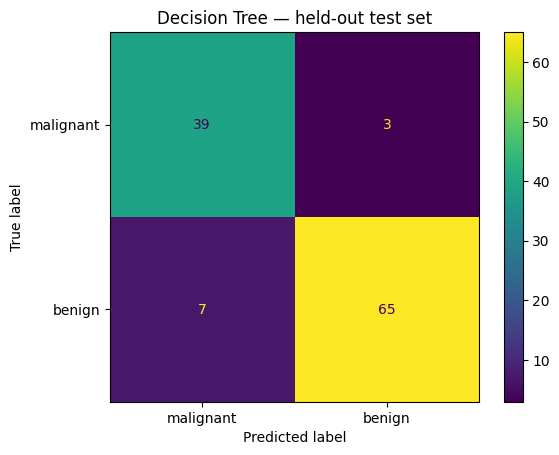

In [3]:
baseline = DecisionTreeClassifier(random_state=RANDOM_STATE)
baseline.fit(X_train, y_train)
baseline_pred = baseline.predict(X_test)

print("Accuracy :", round(accuracy_score(y_test, baseline_pred), 4))
print("Precision:", round(precision_score(y_test, baseline_pred), 4))
print("Recall   :", round(recall_score(y_test, baseline_pred), 4))
print("F1       :", round(f1_score(y_test, baseline_pred), 4))
print(classification_report(y_test, baseline_pred, target_names=dataset.target_names))
ConfusionMatrixDisplay.from_predictions(
    y_test, baseline_pred, display_labels=dataset.target_names, cmap=None
)
plt.title("Decision Tree — held-out test set")
plt.show()

## 3. Compare bagging, Random Forest, and Extra Trees
These methods fit multiple randomized trees and aggregate their predictions. Scores below use only the training split.

In [4]:
models = {
    "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Bagging": BaggingClassifier(
        estimator=DecisionTreeClassifier(random_state=RANDOM_STATE),
        n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1
    ),
    "Extra Trees": ExtraTreesClassifier(
        n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1
    ),
}
rows = []
for name, model in models.items():
    start = time.perf_counter()
    scores = cross_val_score(model, X_train, y_train, cv=cv, scoring="f1", n_jobs=-1)
    rows.append({"model": name, "mean_cv_f1": scores.mean(),
                 "std_cv_f1": scores.std(),
                 "elapsed_seconds": time.perf_counter() - start})
comparison = pd.DataFrame(rows).sort_values("mean_cv_f1", ascending=False)
display(comparison)

Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 785, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 718, in _warm_feature_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 509, in _warm_drawing_and_image_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/generated/interface/models.py", line 32861, in bring_to_front
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/remote.py", line 764, in __call__
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/client.py", line 175, in call
artifact_tool.rpc.client.Remot

Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 785, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 718, in _warm_feature_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 509, in _warm_drawing_and_image_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/generated/interface/models.py", line 32861, in bring_to_front
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/remote.py", line 764, in __call__
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/client.py", line 175, in call
artifact_tool.rpc.client.Remot

Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 785, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 718, in _warm_feature_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 509, in _warm_drawing_and_image_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/generated/interface/models.py", line 32861, in bring_to_front
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/remote.py", line 764, in __call__
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/client.py", line 175, in call
artifact_tool.rpc.client.Remot

Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 785, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 718, in _warm_feature_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 509, in _warm_drawing_and_image_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/generated/interface/models.py", line 32861, in bring_to_front
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/remote.py", line 764, in __call__
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/client.py", line 175, in call
artifact_tool.rpc.client.Remot

Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 785, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 718, in _warm_feature_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 509, in _warm_drawing_and_image_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/generated/interface/models.py", line 32861, in bring_to_front
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/remote.py", line 764, in __call__
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/client.py", line 175, in call
artifact_tool.rpc.client.Remot

,model,mean_cv_f1,std_cv_f1,elapsed_seconds
3,Extra Trees,0.975310,0.015489,0.510011
2,Random Forest,0.970027,0.014628,1.433542
1,Bagging,0.960945,0.015557,1.762827
0,Decision Tree,0.931901,0.014435,9.377376


## 4. Train and compare boosting models
Boosting adds learners sequentially. `learning_rate` and the number of estimators should be considered together.

In [5]:
boosters = {
    "AdaBoost": AdaBoostClassifier(
        n_estimators=100, learning_rate=0.5, random_state=RANDOM_STATE
    ),
    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=100, learning_rate=0.05, random_state=RANDOM_STATE
    ),
}
for name, model in boosters.items():
    scores = cross_val_score(model, X_train, y_train, cv=cv, scoring="f1", n_jobs=-1)
    print(f"{name:20s} mean F1={scores.mean():.4f}, std={scores.std():.4f}")

AdaBoost             mean F1=0.9792, std=0.0130


Gradient Boosting    mean F1=0.9577, std=0.0142


## 5. Voting and stacking
Voting combines model outputs directly. Stacking learns a meta-model from out-of-fold predictions. These methods can cost more and should be justified by validation results.

In [6]:
voting_estimators = [
    ("lr", make_pipeline(SimpleImputer(strategy="median"),
                         LogisticRegression(max_iter=3000))),
    ("rf", RandomForestClassifier(n_estimators=150, random_state=RANDOM_STATE, n_jobs=-1)),
    ("gb", GradientBoostingClassifier(random_state=RANDOM_STATE)),
]
voting = VotingClassifier(estimators=voting_estimators, voting="soft", weights=[1, 2, 1])
stacking = StackingClassifier(
    estimators=voting_estimators,
    final_estimator=LogisticRegression(max_iter=3000),
    cv=5, n_jobs=-1
)
for name, model in {"Soft Voting": voting, "Stacking": stacking}.items():
    scores = cross_val_score(model, X_train, y_train, cv=cv, scoring="f1", n_jobs=-1)
    print(f"{name:15s} mean F1={scores.mean():.4f}, std={scores.std():.4f}")

Soft Voting     mean F1=0.9683, std=0.0134


Stacking        mean F1=0.9667, std=0.0103


## 6. Tune a Random Forest with cross-validation
This search uses the training set only. Keep the test set out of all model-selection decisions.

In [7]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "n_estimators": [100, 250],
    "max_depth": [None, 6, 12],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", 0.7],
}
search = GridSearchCV(
    RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
    param_grid=param_grid, scoring="f1", cv=cv, n_jobs=-1
)
search.fit(X_train, y_train)
print("Best parameters:", search.best_params_)
print("Best mean CV F1:", round(search.best_score_, 4))
best_model = search.best_estimator_

Best parameters: {'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'n_estimators': 250}
Best mean CV F1: 0.9718


## 7. Final held-out evaluation
Evaluate the selected model once on the held-out test set. The score is an estimate for this split, not a guarantee of future performance.

Accuracy : 0.9474
Precision: 0.9583
Recall   : 0.9583
F1       : 0.9583
              precision    recall  f1-score   support

   malignant       0.93      0.93      0.93        42
      benign       0.96      0.96      0.96        72

    accuracy                           0.95       114
   macro avg       0.94      0.94      0.94       114
weighted avg       0.95      0.95      0.95       114



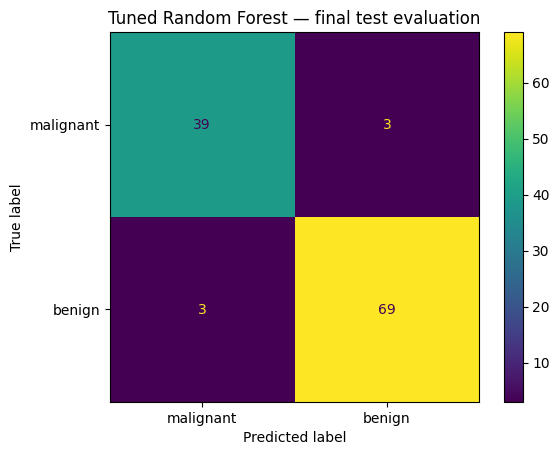

In [8]:
test_pred = best_model.predict(X_test)
print("Accuracy :", round(accuracy_score(y_test, test_pred), 4))
print("Precision:", round(precision_score(y_test, test_pred), 4))
print("Recall   :", round(recall_score(y_test, test_pred), 4))
print("F1       :", round(f1_score(y_test, test_pred), 4))
print(classification_report(y_test, test_pred, target_names=dataset.target_names))
ConfusionMatrixDisplay.from_predictions(
    y_test, test_pred, display_labels=dataset.target_names
)
plt.title("Tuned Random Forest — final test evaluation")
plt.show()

## 8. Inspect feature importance
Impurity-based importance is a useful first diagnostic, but it can favor high-cardinality features and behave unpredictably with correlated features. Consider permutation importance and domain knowledge too.

,impurity_importance
worst perimeter,0.136873
worst area,0.129510
worst concave points,0.112920
worst radius,0.091390
mean concave points,0.090736
mean radius,0.057109
mean perimeter,0.054021
mean concavity,0.045544
mean area,0.043285
worst concavity,0.038144


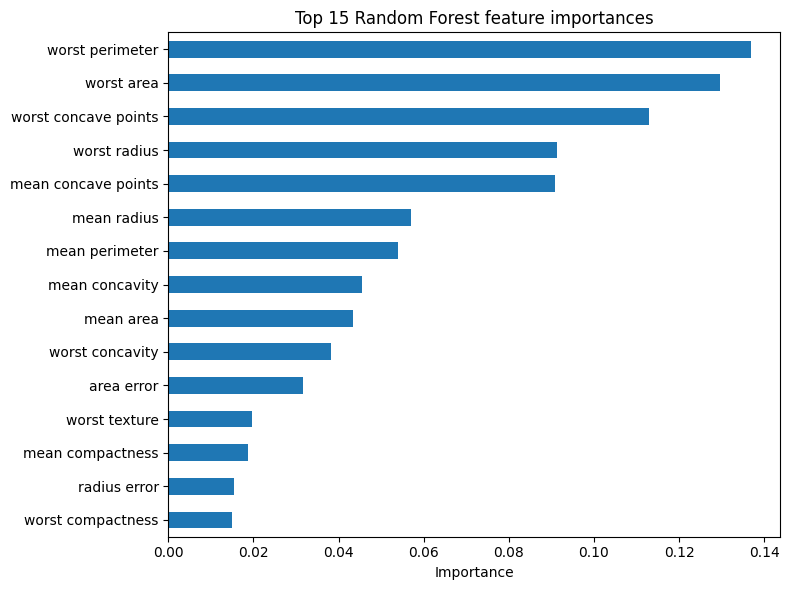

In [9]:
importance = pd.Series(best_model.feature_importances_, index=X_train.columns)
top = importance.sort_values(ascending=False).head(15).sort_values()
display(top.sort_values(ascending=False).to_frame("impurity_importance"))
top.plot(kind="barh", figsize=(8, 6), title="Top 15 Random Forest feature importances")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

## 9. Regression: Random Forest vs Gradient Boosting
The Diabetes dataset is used here to demonstrate regression metrics. MAE/RMSE are in target units; lower is better. R² is relative to a mean-prediction baseline; higher is better.

In [10]:
diabetes = load_diabetes(as_frame=True)
Xr, yr = diabetes.data, diabetes.target
Xr_train, Xr_test, yr_train, yr_test = train_test_split(
    Xr, yr, test_size=0.20, random_state=RANDOM_STATE
)
regressors = {
    "Random Forest": RandomForestRegressor(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1),
    "Gradient Boosting": GradientBoostingRegressor(random_state=RANDOM_STATE),
}
reg_rows = []
for name, model in regressors.items():
    model.fit(Xr_train, yr_train)
    pred = model.predict(Xr_test)
    reg_rows.append({
        "model": name,
        "MAE": mean_absolute_error(yr_test, pred),
        "RMSE": mean_squared_error(yr_test, pred) ** 0.5,
        "R2": r2_score(yr_test, pred),
    })
display(pd.DataFrame(reg_rows).set_index("model").round(3))

,MAE,RMSE,R2
model,,,
Random Forest,44.276,54.461,0.440
Gradient Boosting,44.603,53.837,0.453


## 10. Reflection and next steps
1. Did any ensemble consistently beat the decision-tree baseline across folds?
2. How much variation was there across CV folds?
3. Which metric best represents the task's real-world costs?
4. Did tuning improve cross-validation performance, and at what compute cost?
5. What additional validation, monitoring, or fairness checks would be required before deployment?

**Takeaway:** select an ensemble because reliable validation evidence supports it—not because it is more complex.